In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "src").is_dir() and (parent / "utils" / "paths.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from utils.paths import DATA_DIR, EXPERIMENTS_DIR

%load_ext autoreload
%autoreload 2

from utils import data_loading as data
from src import meg_segmentation as mseg
from utils import segmentation_plots as plots
OUTPUT_DIR = EXPERIMENTS_DIR / "demo"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# Load data
epochs = data.load_sample_epochs(condition="visual/left")
print(epochs)
meg_channels = [ch for ch in epochs.ch_names if ch.startswith('MEG')]
print('MEG channel names:', ', '.join(meg_channels))  

<Epochs | 73 events (all good), -0.1 – 0.499 s (baseline -0.1 – 0 s), ~78.8 MiB, data loaded,
 'visual/left': 73>
MEG channel names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG 0132, MEG 0133, MEG 0131, MEG 0143, MEG 0142, MEG 0141, MEG 0213, MEG 0212, MEG 0211, MEG 0222, MEG 0223, MEG 0221, MEG 0232, MEG 0233, MEG 0231, MEG 0243, MEG 0242, MEG 0241, MEG 0313, MEG 0312, MEG 0311, MEG 0322, MEG 0323, MEG 0321, MEG 0333, MEG 0332, MEG 0331, MEG 0343, MEG 0342, MEG 0341, MEG 0413, MEG 0412, MEG 0411, MEG 0422, MEG 0423, MEG 0421, MEG 0432, MEG 0433, MEG 0431, MEG 0443, MEG 0442, MEG 0441, MEG 0513, MEG 0512, MEG 0511, MEG 0523, MEG 0522, MEG 0521, MEG 0532, MEG 0533, MEG 0531, MEG 0542, MEG 0543, MEG 0541, MEG 0613, MEG 0612, MEG 0611, MEG 0622, MEG 0623, MEG 0621, MEG 0633, MEG 0632, MEG 0631, MEG 0642, MEG 0643, MEG 0641, MEG 0713, MEG 0712, MEG 0711, MEG 0723, MEG 0722, MEG 0721, MEG 0733, MEG 0732, MEG 0731, MEG 0743, MEG 0742, MEG 0741, MEG 0813, MEG 0812, MEG 081

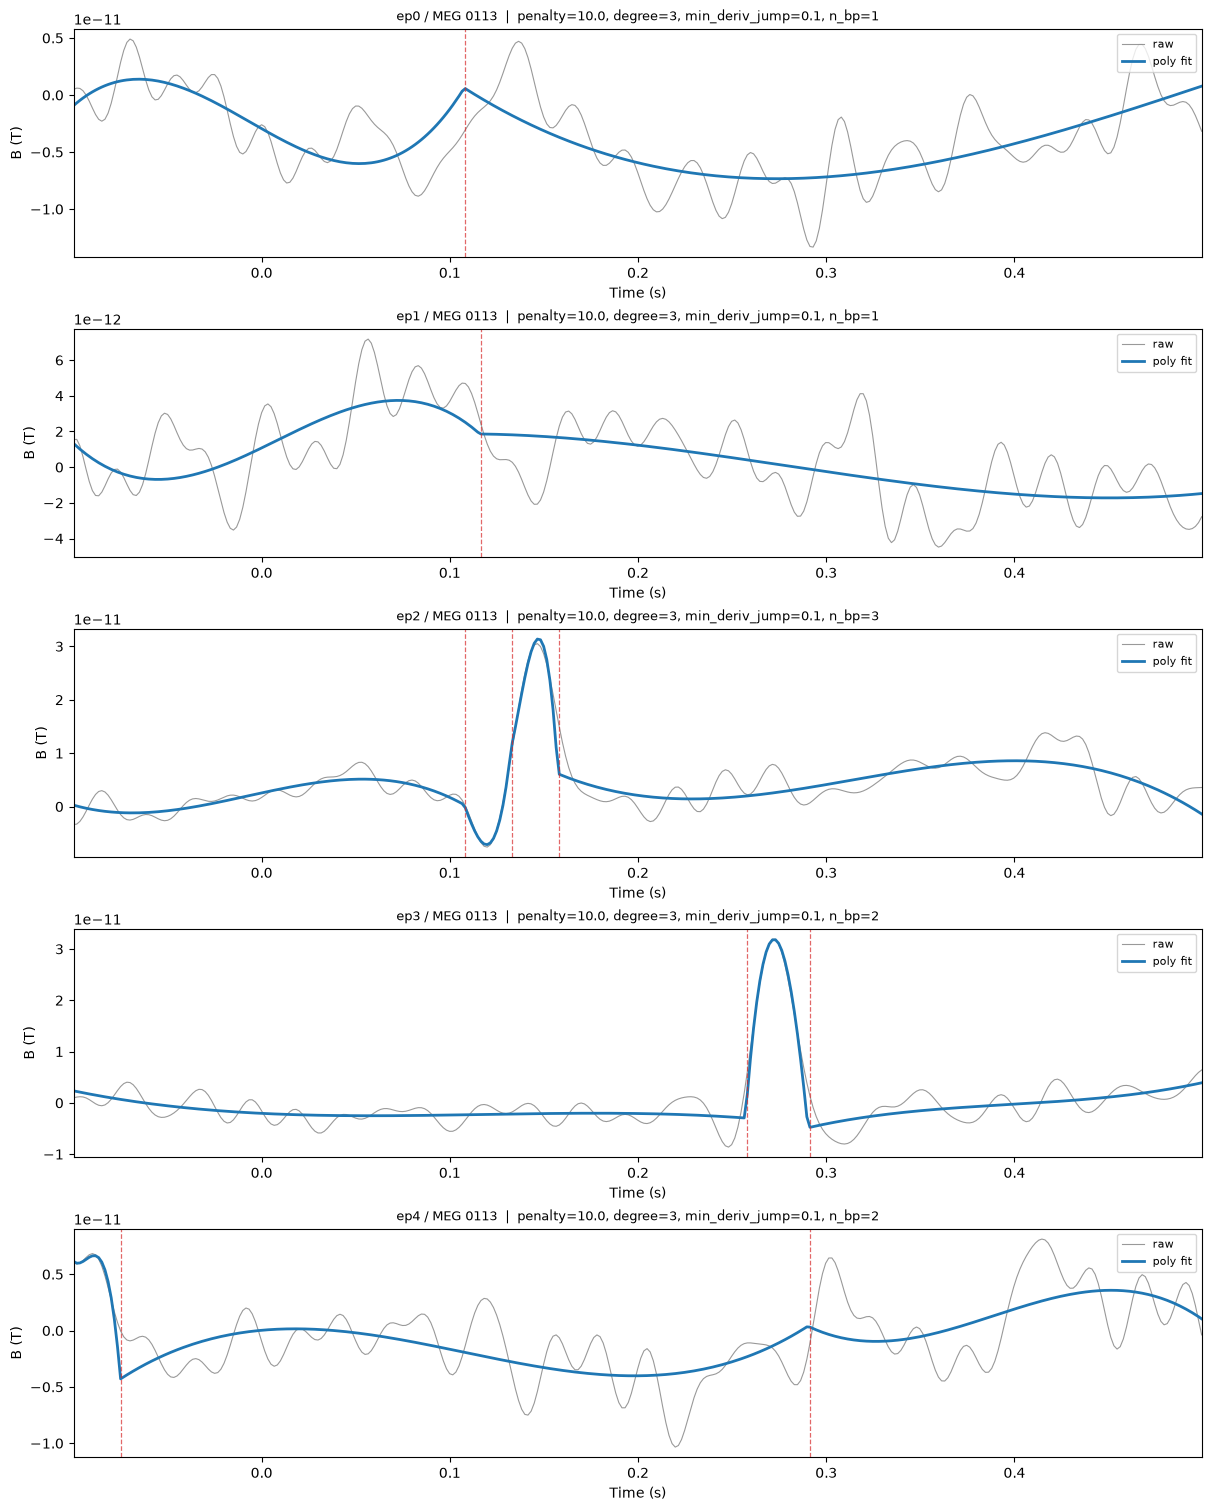

In [3]:
# Option A - reproducible, explicit (epoch, channel) pairs
series = data.select_series(
    epochs,
    epoch_indices=range(5),
    channel_names=['MEG 0113']*5, #["EEG 001", "MEG 1711", "MEG 2341", "MEG 1931"],
)

# Option B - random selection 
# series = data.select_series(epochs, epoch_indices=None, channel_names=None, n_random=5, seed=42)

results = [mseg.segment_and_fit(s["signal"], penalty=10.0, degree=3, min_deriv_jump=0.1) for s in series]
plots.plot_multiple(series, results, save_dir=str(OUTPUT_DIR));